##Evidencia 3: Econometría I
Del 16 de marzo al 13 de mayo de 2026



## Índice
[Objetivo del análisis_19](#objetivo_19)

[Código y Resultados clave_19](#codigo_19)

[Aprendizajes obtenidos_19](#apren_19)

[Objetivo del análisis_20](#objetivo_20)

[Código y Resultados clave_20](#codigo_20)

[Aprendizajes obtenidos_20](#apren_20)

[Objetivo del análisis_21](#objetivo_21)

[Código y Resultados clave_21](#codigo_21)

[Aprendizajes obtenidos_21](#apren_21)

[Objetivo del análisis_22](#objetivo_22)

[Código y Resultados clave_22](#codigo_22)

[Aprendizajes obtenidos_22](#apren_22)

[Objetivo del análisis_23](#objetivo_23)

[Código y Resultados clave_23](#codigo_23)

[Aprendizajes obtenidos_23](#apren_23)

[Objetivo del análisis_24](#objetivo_24)

[Aprendizajes obtenidos_24](#apren_24)

[Código y Resultados clave_24](#codigo_24)

[Conclusión](#co)

#Objetivo del análisis <a name="objetivo_19"></a>
Durante la sesión analizamos el impacto de la endogeneidad en las finanzas, utilizando como caso práctico la interacción entre la toma de riesgos de una empresa y los bonos de sus directivos. Contrastamos los métodos OLS, 2SLS y 3SLS para evidenciar que, cuando las variables se determinan mutuamente, ignorar el sesgo de simultaneidad genera estimaciones engañosas que solo pueden corregirse mediante sistemas de ecuaciones

##Sesion 19


#Código y Resultados clave <a name="codigo_19"></a>

In [ ]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 10.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from linearmodels.iv import IV2SLS

In [ ]:
np.random.seed(123)
n = 500

# Exógenas
LTA = np.random.normal(10, 0.5, n)
Capital = np.random.normal(0.10, 0.02, n)
NI = np.random.normal(0.30, 0.05, n)
SP = np.random.normal(50, 10, n)

# Shock latente MUY fuerte (fuente principal de endogeneidad)
omega = np.random.normal(0, 1.5, n)

# Errores altamente correlacionados
u = 1.2*omega + np.random.normal(0, 1, n)
v = 1.2*omega + np.random.normal(0, 1, n)

# Compensación (endógena)
Comp = 0.6*SP + 0.3*LTA + v

# Riesgo: efecto verdaderp PEQUEÑO
Risk = 0.08*Comp -  0.6*Capital + 0.2*NI + u

data = pd.DataFrame({
    "Risk": Risk,
    "Comp": Comp,
    "LTA": LTA,
    "Capital": Capital,
    "NI": NI,
    "SP": SP
})


In [ ]:
# Estimación por OLS
x_ols = sm.add_constant(data[["Comp", "LTA", "Capital", "NI"]])
y_ols = data["Risk"]

ols_model = sm.OLS(y_ols, x_ols).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   Risk   R-squared:                       0.213
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     33.50
Date:                Fri, 15 May 2026   Prob (F-statistic):           9.60e-25
Time:                        23:19:36   Log-Likelihood:                -1044.3
No. Observations:                 500   AIC:                             2099.
Df Residuals:                     495   BIC:                             2120.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2676      2.013     -0.133      0.8

In [ ]:
iv_model = IV2SLS(
  dependent=data["Risk"],
  exog=sm.add_constant(data[["LTA", "Capital", "NI"]]),
  endog=data["Comp"],
  instruments=data[["SP"]]
).fit()

print(iv_model.summary)

                          IV-2SLS Estimation Summary                          
Dep. Variable:                   Risk   R-squared:                      0.1636
Estimator:                    IV-2SLS   Adj. R-squared:                 0.1569
No. Observations:                 500   F-statistic:                    33.287
Date:                Fri, May 15 2026   P-value (F-stat)                0.0000
Time:                        23:19:36   Distribution:                  chi2(4)
Cov. Estimator:                robust                                         
                                                                              
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
const          2.5478     2.1022     1.2120     0.2255     -1.5724      6.6680
LTA           -0.2890     0.1806    -1.5997     0.10

In [ ]:
results = pd.DataFrame({
    "OLS": ols_model.params,
    "2SLS": iv_model.params,
})

In [ ]:
from linearmodels.system import IV3SLS

In [ ]:
equations = {
  "Risk_eq": {
    "dependent": data["Risk"],
    "exog": sm.add_constant(data[["LTA", "Capital", "NI"]]),
    "endog": data[["Comp"]],
    "instruments": data[["SP"]]
  },
  "Comp_eq": {
    "dependent": data["Comp"],
    "exog": sm.add_constant(data[["LTA"]]),
    "endog": data[["Risk"]],
    "instruments": data[["SP"]]
  }
}

In [ ]:
model_3sls = IV3SLS(equations)
results_3sls = model_3sls.fit()
print(results_3sls)

                           System GLS Estimation Summary                           
Estimator:                        GLS   Overall R-squared:                  -12.803
No. Equations.:                     2   McElroy's R-squared:                 0.9993
No. Observations:                 500   Judge's (OLS) R-squared:            -12.803
Date:                Fri, May 15 2026   Berndt's R-squared:                  0.9910
Time:                        23:19:36   Dhrymes's R-squared:                -12.803
                                        Cov. Estimator:                      robust
                                        Num. Constraints:                      None
                 Equation: Risk_eq, Dependent Variable: Risk                  
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
const          2.5691     1.9175     1.3398     0.1803     -1.1891      6.3273
LTA         

In [ ]:
comparasion = pd.DataFrame({
    "OLS": ols_model.params,
    "2SLS": iv_model.params,
    "3SLS (Risk eq)": results_3sls.equations["Risk_eq"].params
})
comparasion

,OLS,2SLS,3SLS (Risk eq)
Capital,0.564357,1.615028,1.982085
Comp,0.157710,0.080180,0.080246
LTA,-0.227650,-0.288976,-0.290419
NI,-0.046075,0.752245,0.602084
const,-0.267575,2.547755,2.569074


Vemos que el parámetro asociado a la variable de compensación ejecutiva (Comp) mide su impacto directo sobre el nivel de riesgo corporativo. Al emplear Mínimos Cuadrados Ordinarios (OLS), se obtuvo un coeficiente de 0.1577, el cual se redujo a aproximadamente a 0.080 al aplicar los métodos 2SLS y 3SLS. Esta diferencia evidencia que el OLS sobreestimaba la magnitud del efecto a causa de la endogeneidad. Metodológicamente, el 2SLS solventa este sesgo empleando el precio de la acción (SP) como variable instrumental, mientras que el 3SLS aporta mayor eficiencia al incorporar la información cruzada del sistema de ecuaciones. Y según la perspectiva económica, la principal implicación es que las variables financieras que se determinan de forma simultánea no deben interpretarse como relaciones causales directas sin un tratamiento econométrico adecuado.

#Aprendizajes obtenidos <a name="apren_19"></a>


Temas más importantes:

1. Endogeneidad y simultaneidad.
2. Uso de variables instrumentales.
3. Comparación entre OLS, 2SLS y 3SLS.
4. Interpretación causal de coeficientes financieros.

Este aprendizaje puede aplicarse en finanzas corporativas, por ejemplo, para estudiar la relación entre compensación ejecutiva y riesgo, deuda y rentabilidad, inversión y valor de mercado, o cualquier caso donde dos variables se afecten mutuamente.

---
**Sesión 20**

#Objetivo del análisis <a name="objetivo_20"></a>


Durante esta sesión, desarrollamos un modelo dinámico de toma de decisiones financieras fundamentado en la identidad contable de fuentes y usos de fondos. El análisis abarcó variables clave como la política de dividendos, las inversiones a corto y largo plazo, así como la estructura de deuda y el financiamiento mediante capital. Para capturar rigurosamente la interdependencia estructural entre estas decisiones, implementamos metodologías econométricas de sistemas, específicamente los modelos de Regresión Aparentemente Inconexa (SUR) y Mínimos Cuadrados de Tres Etapas (3SLS).

#Código y Resultados clave <a name="codigo_20"></a>

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(123)

T = 60 # Número de periodos

# Variables exógenas
Y   = np.random.normal(100, 10, T)
RCB = np.random.normal(0.06, 0.01, T)
RDP = np.random.normal(0.04, 0.005, T)
DEL = np.random.normal(0.8, 0.1, T)
R   = np.random.normal(0.12, 0.02, T)
CU  = np.random.normal(0.85, 0.05, T)

Z = np.column_stack([np.ones(T), Y, RCB, RDP, DEL, R, CU])

# Matriz A (presupuesto óptimo)
A = np.array([
  [0.2,  0.30, -5.0,  2.0, -1.0,  1.5,  0.5],   # DIV*
  [0.1,  0.25, -3.0,  1.0, -0.5,  1.0,  0.3],   # IST*
  [0.05, 0.35, -4.0,  1.5, -1.2,  2.0,  0.6],   # ILT*
  [0.3, -0.50,  6.0, -2.5,  2.0, -1.0, -0.2],   # DF*
  [0.35,-0.40,  6.0, -2.0,  1.7, -1.0, -0.2]    # EQF*
])

X_star = Z @ A.T

# Normalizar para cumplir fuentes = usos
X_star = X_star * (Y / X_star.sum(axis=1))[:, None]

In [ ]:
D = np.array([
    [0.6,  0.1,  0.1,  0.1,  0.1],
    [0.2,  0.4,  0.2,  0.1,  0.1],
    [0.1,  0.2,  0.5,  0.1,  0.1],
    [0.05, 0.15, 0.15, 0.55, 0.10],
    [0.05, 0.15, 0.05, 0.15, 0.60]
  ])

# Inicialización
X = np.zeros((T, 5))
X[0, :] = X_star[0, :] + np.random.normal(0, 1, 5)

# Dinámica
for t in range(1, T):
  X[t] = X[t-1] + D @ (X_star[t] - X[t-1]) + np.random.normal(0, 0.5, 5)

df = pd.DataFrame(
  X, columns=["DIV", "IST", "ILT", "DF", "EQF"]
)
df["Y"] = Y


In [ ]:
df["Suma"] = df[["DIV","IST","ILT","DF","EQF"]].sum(axis=1)
(df["Suma"] - df["Y"]).abs().mean()

np.float64(0.9453546714547223)

Parte C. Estimación

In [ ]:
import statsmodels.api as sm

df_lag = df.shift(1).dropna()
Y_est = df_lag[["DIV","IST","ILT","DF","EQF"]]
X_est = sm.add_constant(df_lag[["DIV","IST","ILT","DF","EQF"]])

results = {}
for col in Y_est.columns:
  model = sm.OLS(Y_est[col], X_est).fit()
results[col] = model
print("\n", col)
print(model.summary())



 EQF
                            OLS Regression Results                            
Dep. Variable:                    EQF   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 6.353e+27
Date:                Fri, 15 May 2026   Prob (F-statistic):               0.00
Time:                        23:19:36   Log-Likelihood:                 1413.1
No. Observations:                  59   AIC:                            -2814.
Df Residuals:                      53   BIC:                            -2802.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       6.821e-13   2.22e-11      0.031   

In [ ]:
!pip install linearmodels

from linearmodels.system import SUR
import pandas as pd
import statsmodels.api as sm

In [ ]:
df_sur = df.copy()

# Rezagos
for v in ["DIV", "IST", "ILT", "DF", "EQF"]:
  df_sur[f"{v}_lag"] = df_sur[v].shift(1)

df_sur = df_sur.dropna()

In [ ]:
exog_vars = ["DIV_lag", "IST_lag", "ILT_lag", "DF_lag", "EQF_lag"]

equations = {
  "DIV": (
    df_sur["DIV"],
    sm.add_constant(df_sur[exog_vars])
  ),
  "IST": (
    df_sur["IST"],
    sm.add_constant(df_sur[exog_vars])
  ),
  "ILT": (
    df_sur["ILT"],
    sm.add_constant(df_sur[exog_vars])
  ),
  "DF": (
    df_sur["DF"],
    sm.add_constant(df_sur[exog_vars])
  ),
  "EQF": (
    df_sur["EQF"],
    sm.add_constant(df_sur[exog_vars])
  )
}


In [ ]:
sur_model = SUR(equations)
sur_results = sur_model.fit()

print(sur_results.summary)

                           System GLS Estimation Summary                           
Estimator:                        GLS   Overall R-squared:                   0.4207
No. Equations.:                     5   McElroy's R-squared:                 0.9995
No. Observations:                  59   Judge's (OLS) R-squared:             0.4207
Date:                Fri, May 15 2026   Berndt's R-squared:                  1.0000
Time:                        23:19:46   Dhrymes's R-squared:                 0.4207
                                        Cov. Estimator:                      robust
                                        Num. Constraints:                      None
                    Equation: DIV, Dependent Variable: DIV                    
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
const          140.36     242.06     0.5799     0.5620     -334.06      614.78
DIV_lag     

In [ ]:
sur_results.resids.corr()

,DIV,IST,ILT,DF,EQF
DIV,1.000000,0.999974,0.999984,-0.999974,-0.999980
IST,0.999974,1.000000,0.999984,-0.999958,-0.999960
ILT,0.999984,0.999984,1.000000,-0.999972,-0.999975
DF,-0.999974,-0.999958,-0.999972,1.000000,0.999992
EQF,-0.999980,-0.999960,-0.999975,0.999992,1.000000


In [ ]:
from linearmodels.system import IV3SLS
import statsmodels.api as sm
import pandas as pd

# Rezagos
df_3sls = df.copy()
for v in ["DIV", "IST", "ILT", "DF", "EQF"]:
  df_3sls[f"{v}_lag"] = df_3sls[v].shift(1)

df_3sls = df_3sls.dropna()


In [ ]:
exog = sm.add_constant(df_3sls[["Y"]])

endog_rhs = df_3sls[["DIV_lag","IST_lag","ILT_lag","DF_lag","EQF_lag"]]

# Create a DataFrame for the excluded instruments
# These are RCB, RDP, DEL, R, CU, which were originally created for T periods
# We need to slice them to match the length of df_3sls (T-1 periods)
excluded_instruments_data = {
    'RCB': RCB[1:],
    'RDP': RDP[1:],
    'DEL': DEL[1:],
    'R': R[1:],
    'CU': CU[1:]
}
# Create the DataFrame and ensure its index matches df_3sls
excluded_instruments = pd.DataFrame(excluded_instruments_data, index=df_3sls.index)


equations_3sls = {
  "DIV": {
    "dependent": df_3sls["DIV"],
    "exog": exog,
    "endog": endog_rhs,
    "instruments": excluded_instruments
  },
  "IST": {
    "dependent": df_3sls["IST"],
    "exog": exog,
    "endog": endog_rhs,
    "instruments": excluded_instruments
  },
  "ILT": {
    "dependent": df_3sls["ILT"],
    "exog": exog,
    "endog": endog_rhs,
    "instruments": excluded_instruments
  },
  "DF": {
    "dependent": df_3sls["DF"],
    "exog": exog,
    "endog": endog_rhs,
    "instruments": excluded_instruments
  },
  "EQF": {
    "dependent": df_3sls["EQF"],
    "exog": exog,
    "endog": endog_rhs,
    "instruments": excluded_instruments
  }
}


In [ ]:
model_3sls = IV3SLS(equations_3sls)
results_3sls = model_3sls.fit()

print(results_3sls.summary)

                           System OLS Estimation Summary                           
Estimator:                        OLS   Overall R-squared:                  -0.4701
No. Equations.:                     5   McElroy's R-squared:                 0.9989
No. Observations:                  59   Judge's (OLS) R-squared:            -0.4701
Date:                Fri, May 15 2026   Berndt's R-squared:                  0.9999
Time:                        23:19:46   Dhrymes's R-squared:                -0.4701
                                        Cov. Estimator:                      robust
                                        Num. Constraints:                      None
                    Equation: DIV, Dependent Variable: DIV                    
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
const         -49.507  1.058e+04    -0.0047     0.9963  -2.079e+04   2.069e+04
Y           


Podemos observar 4 puntos importantes:

Equilibrio financiero: Por la regla de fuentes y usos, si se modifica una variable (como la deuda o los dividendos), el resto del sistema debe ajustarse forzosamente para cuadrar el balance.

Correlación SUR: El modelo detectó una fuerte correlación en los errores de las ecuaciones, probando que estas decisiones corporativas están íntimamente entrelazadas.

Ajuste del sistema: La capacidad explicativa global es casi perfecta.

Problema (Multicolinealidad): A pesar del buen ajuste global, los errores estándar inusualmente altos en algunos coeficientes indican que varias variables podrían estar excesivamente correlacionadas entre sí."

#Aprendizajes obtenidos <a name="apren_20"></a>

Sesgo por endogeneidad y causalidad simultánea.

Implementación y validez de variables instrumentales.

Contraste metodológico: OLS frente a sistemas 2SLS y 3SLS.

Inferencia causal estricta en parámetros financieros.

Aplicación Práctica:
Estas herramientas econométricas son fundamentales para modelar sistemas donde las variables se retroalimentan. El marco analítico permite resolver relaciones bidireccionales complejas, tales como la interacción entre la estructura de bonos directivos y la exposición al riesgo, la dinámica entre endeudamiento y rentabilidad, o el impacto mutuo entre las decisiones de inversión y el valor de mercado.

##Sesion 21

#Objetivo del análisis <a name="objetivo_21"></a>

Durante esta clase analizamos la metodología de datos de panel, contrastando los enfoques de OLS, efectos fijos y efectos aleatorios. El propósito principal fue evaluar de qué manera las características inobservables propias de cada compañía influyen en el cálculo de métricas financieras, tomando como caso de estudio la cotización de sus acciones.


#Código y Resultados clave <a name="codigo_21"></a>

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(123)

# Dimensiones del panel
n_firms = 30
n_years = 8

firms = np.arange(n_firms)
years = np.arange(n_years)

panel = [(i, t) for i in firms for t in years]
df = pd.DataFrame(panel, columns = ["firm", "year"])

# Efectos no observables
firm_effect = np.random.normal(0, 1.5, n_firms)
time_effect = np.random.normal(0, 1.0, n_years)

df["w_i"] = df["firm"].map(dict(zip(firms, firm_effect)))
df["v_t"] = df["year"].map(dict(zip(years, time_effect)))

# Variables explicativas
df["dividends"] = np.random.uniform(0.5, 3.0, len(df))
df["retained"] = np.random.uniform(1.0, 5.0, len(df))

# Error idiosincrático
df["u_it"] = np.random.normal(0, 1, len(df))

# Variable dependiente (precio)
df["price"] = (
  5
  + 1.8 * df["dividends"]
  + 0.9 * df["retained"]
  + df["w_i"]
  + df["v_t"]
  + df["u_it"]
)

df.head()


,firm,year,w_i,v_t,dividends,retained,u_it,price
0,0,0,-1.628446,-0.255619,2.059882,4.550374,-1.380351,9.538708
1,0,1,-1.628446,-2.798589,0.789046,1.064475,1.698059,4.649334
2,0,2,-1.628446,-1.771533,1.293214,1.507832,-0.688549,4.596306
3,0,3,-1.628446,-0.699877,1.537066,4.108650,-1.084769,8.051411
4,0,4,-1.628446,0.927462,2.665773,1.183581,-0.456426,9.706205


In [ ]:
import statsmodels.api as sm

X_ols = df[["dividends", "retained"]]
X_ols = sm.add_constant(X_ols)
y = df["price"]

ols_model = sm.OLS(y, X_ols).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.363
Model:                            OLS   Adj. R-squared:                  0.357
Method:                 Least Squares   F-statistic:                     67.41
Date:                Fri, 15 May 2026   Prob (F-statistic):           6.64e-24
Time:                        23:19:46   Log-Likelihood:                -545.44
No. Observations:                 240   AIC:                             1097.
Df Residuals:                     237   BIC:                             1107.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.4017      0.550      8.007      0.0

Modelo de Efectos Fijos (FE)

In [ ]:
firm_dummies = pd.get_dummies(df["firm"], drop_first=True, dtype=int)

X_fe = pd.concat([df[["dividends", "retained"]], firm_dummies], axis=1)
X_fe = sm.add_constant(X_fe)

fe_model = sm.OLS(y, X_fe).fit()
print(fe_model.summary())


                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.719
Method:                 Least Squares   F-statistic:                     20.77
Date:                Fri, 15 May 2026   Prob (F-statistic):           5.57e-48
Time:                        23:19:46   Log-Likelihood:                -430.29
No. Observations:                 240   AIC:                             924.6
Df Residuals:                     208   BIC:                             1036.
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.4044      0.669      3.596      0.0

Modelo de Efectos Aleatorios

In [ ]:
from statsmodels.regression.mixed_linear_model import MixedLM

re_model = MixedLM(
    df["price"],
    sm.add_constant(df[["dividends", "retained"]]),
    groups = df["firm"]
).fit()

print(re_model.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: price    
No. Observations: 240     Method:             REML     
No. Groups:       30      Scale:              2.4373   
Min. group size:  8       Log-Likelihood:     -485.3064
Max. group size:  8       Converged:          Yes      
Mean group size:  8.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
const         4.302    0.497  8.654 0.000  3.328  5.277
dividends     2.045    0.150 13.658 0.000  1.752  2.339
retained      0.864    0.089  9.720 0.000  0.690  1.039
Group Var     3.218    0.633                           



Comparación

In [ ]:
fe_coef = fe_model.params[["dividends", "retained"]]
re_coef = re_model.params[["dividends", "retained"]]

comparison = pd.DataFrame({
  "FE": fe_coef,
  "RE": re_coef,
  "Difference": fe_coef - re_coef
})

comparison


,FE,RE,Difference
dividends,2.050619,2.045182,0.005437
retained,0.864750,0.864490,0.000260


Con esto observamos que el parámetro de los dividendos rondó el valor de 2, indicando que mayores repartos se vinculan en promedio con un alza en la cotización bursátil. Por su parte, el estimador de las utilidades retenidas se situó cerca de 0.86, reflejando que retener ganancias también impacta positivamente en el valor de la acción. Respecto a la bondad de ajuste, el método clásico (OLS) obtuvo un R-cuadrado de 0.363, mientras que la estimación por efectos fijos escaló a 0.756. Este contraste evidencia que controlar por las características inobservables propias de cada empresa optimiza significativamente la capacidad explicativa del modelo

#Aprendizajes obtenidos <a name="apren_21"></a>
Estructuras de datos de panel.

Factores corporativos inobservables.

Comparativa metodológica: Mínimos Cuadrados Ordinarios frente a modelos de Efectos Fijos y Efectos Aleatorios.

Relevancia de ajustar los modelos por la heterogeneidad entre compañías.

Aplicación práctica:
Estas herramientas son fundamentales en el sector financiero para dar seguimiento a las organizaciones a través del tiempo, permitiendo analizar métricas como la cotización bursátil, márgenes de ganancia, políticas de dividendos y niveles de inversión o apalancamiento. Asimismo, son altamente útiles en el diseño y evaluación de políticas públicas, donde facilitan el contraste temporal entre distintas regiones, estados o naciones.


##Sesion 22

#Objetivo del análisis <a name="objetivo_22"></a>
Durante este bloque abordamos la inferencia estadística aplicada a datos de panel, haciendo un énfasis particular en la estimación de errores estándar agrupados (clúster) a nivel empresa y en la ejecución del test de Hausman como criterio estadístico para elegir entre un modelo de efectos fijos o uno de efectos aleatorios.

#Código y Resultados clave <a name="codigo_22"></a>

In [ ]:
cluster_se = fe_model.get_robustcov_results(
    cov_type = "cluster",
    groups = df["firm"]
)

print(cluster_se.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.719
Method:                 Least Squares   F-statistic:                     285.6
Date:                Fri, 15 May 2026   Prob (F-statistic):           8.29e-20
Time:                        23:19:46   Log-Likelihood:                -430.29
No. Observations:                 240   AIC:                             924.6
Df Residuals:                     208   BIC:                             1036.
Df Model:                          31                                         
Covariance Type:              cluster                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.4044      0.473      5.083      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 31, but rank is 2
  warnings.warn('covariance of constraints does not have full '


In [ ]:
import numpy as np
from scipy import stats
from linearmodels import PanelOLS, RandomEffects
import statsmodels.api as sm

# Convertir el DataFrame a un PanelOLS compatible (requiere MultiIndex)
df_panel = df.set_index(['firm', 'year'])

y_panel = df_panel['price']
X_panel = sm.add_constant(df_panel[['dividends', 'retained']])

# Estimar modelo de Efectos Fijos (FE)
fe_lm = PanelOLS(y_panel, X_panel, entity_effects=True)
fe_res = fe_lm.fit()

# Estimar modelo de Efectos Aleatorios (RE)
re_lm = RandomEffects(y_panel, X_panel)
re_res = re_lm.fit()

# Realizamos la prueba de Hausman manualmente
# Extraer coeficientes para las variables comunes (excluyendo la constante si no es comparable)
common_params = ['dividends', 'retained']

b_fe = fe_res.params[common_params]
b_re = re_res.params[common_params]

# Extraer matrices de covarianza para estos parámetros comunes
cov_fe = fe_res.cov.loc[common_params, common_params]
cov_re = re_res.cov.loc[common_params, common_params]

# Calcular la diferencia en coeficientes
diff_coef = b_fe - b_re

#Calcular la diferencia en matrices de covarianza ( Var(b_FE) - Var(b_RE))
diff_cov = cov_fe - cov_re

try:
    # Invertir la diferencia en matrices de covarianza
    inv_diff_cov = np.linalg.inv(diff_cov)

    # Calcular el estadístico de Hausman
    hausman_stat = diff_coef.T @ inv_diff_cov @ diff_coef

    # Grados de libertad (número de parámetros comunes)
    df = len(common_params)

    # Calcular el p-valor
    p_value = 1 - stats.chi2.cdf(hausman_stat, df)

    print("\n--- Resultado de la Prueba de Hausman ---")
    print(f"Estadístico de Hausman: {hausman_stat:.4f}")
    print(f"Grados de Libertad: {df}")
    print(f"P-valor: {p_value:.4f}")

    if p_value < 0.05:
        print("Conclusión: Se rechaza la Hipótesis Nula. El modelo de Efectos Fijos es preferido.")
        print("(Los efectos individuales están correlacionados con los regresores).")
    else:
        print("Conclusión: No se rechaza la Hipótesis Nula. El modelo de Efectos Aleatorios es preferido.")
        print("(Los efectos individuales no están correlacionados con los regresores y es más eficiente).")

except np.linalg.LinAlgError:
    print("\n--- Resultado de la Prueba de Hausman ---")
    print("Error: La diferencia en las matrices de covarianza no es invertible.")
    print("Esto a menudo sugiere que la varianza de los coeficientes de Efectos Aleatorios es menor que la de Efectos Fijos (Cov(b_RE) < Cov(b_FE)).")
    print("En este caso, la prueba de Hausman puede ser inválida, pero suele implicar que el modelo de Efectos Aleatorios es más eficiente y, por lo tanto, el preferido.")
    print("Conclusión: El modelo de Efectos Aleatorios es preferido (probablemente más eficiente y consistente).")



--- Resultado de la Prueba de Hausman ---
Estadístico de Hausman: 0.0736
Grados de Libertad: 2
P-valor: 0.9638
Conclusión: No se rechaza la Hipótesis Nula. El modelo de Efectos Aleatorios es preferido.
(Los efectos individuales no están correlacionados con los regresores y es más eficiente).


El uso de errores estándar tipo clúster corrige la posible autocorrelación de los residuos al interior de cada firma. Esta validación es fundamental, ya que la presencia de dependencia temporal volvería inexactos a los errores estándar tradicionales del método OLS. Por otro lado, el estadístico de Hausman arrojó un valor p cercano a 0.9638, lo que impide rechazar la hipótesis nula. La implicación econométrica de esto es que la heterogeneidad inobservable de las empresas es independiente de las variables explicativas; en consecuencia, resulta estadísticamente más eficiente decantarse por el modelo de efectos aleatorios.

#Aprendizajes obtenidos <a name="apren_22"></a>

Estimación de errores estándar robustos y agrupamiento (clustering) a nivel empresa.

Ejecución e interpretación de la prueba de Hausman.

Criterios estadísticos para decidir entre modelos de efectos fijos y aleatorios.

Técnicas para garantizar una inferencia válida en estructuras longitudinales.

Uso práctico:
Estas competencias son directamente aplicables en el análisis de corporativos, instituciones bancarias, compañías de seguros o carteras de inversión. De igual manera, resultan invaluables en la evaluación de políticas económicas para medir el impacto de programas gubernamentales utilizando observaciones anualizadas a nivel estatal o municipal.

##Sesion 23


#Objetivo del análisis <a name="objetivo_23"></a>

Durante esta sesión analizamos el impacto estadístico de los errores de medición en las variables independientes, abordado a través de los modelos EIV (Errors-in-Variables). El enfoque principal fue demostrar matemáticamente cómo las mediciones imprecisas generan un sesgo de atenuación, el cual distorsiona el coeficiente estimado empujándolo hacia cero.

#Código y Resultados clave <a name="codigo_23"></a>



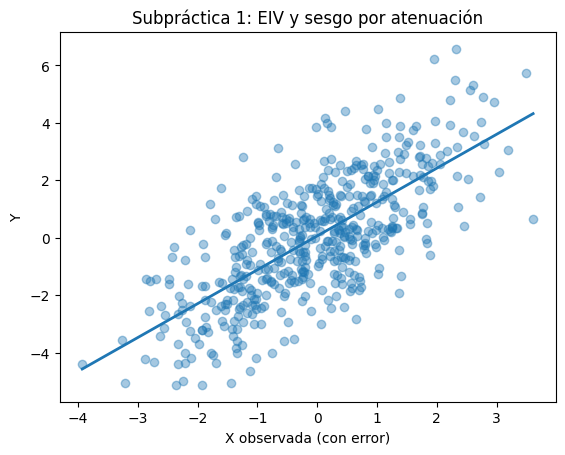

Coeficiente verdadero: 2
Coeficiente MCO: 1.177702358752542


In [ ]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

np.random.seed(123)

n = 500
U = np.random.normal(0, 1, n)
e = np.random.normal(0, 0.8, n)
g = np.random.normal(0, 1, n)

b_true = 2
V = b_true * U
X = U + e
Y = V + g

# MCO
X_ols = sm.add_constant(X)
model_ols = sm.OLS(Y, X_ols).fit()

# Gráfico
plt.figure()
plt.scatter(X, Y, alpha=0.4)
plt.plot(np.sort(X),
         model_ols.params[0] + model_ols.params[1]*np.sort(X),
         linewidth=2)
plt.title("Subpráctica 1: EIV y sesgo por atenuación")
plt.xlabel("X observada (con error)")
plt.ylabel("Y")
plt.show()

print("Coeficiente verdadero:", b_true)
print("Coeficiente MCO:", model_ols.params[1])


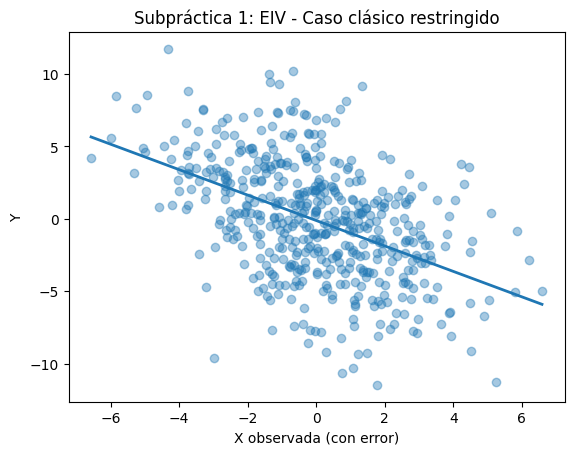

Coeficiente verdadero: -4
Coeficiente MCO: -0.8780052820430946


In [ ]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

np.random.seed(456)

n = 500
U = np.random.normal(0, 1, n)
e = np.random.normal(0, 2.0, n) # Error de medición en X
g = np.zeros(n)                 # Restringuido

b_true = -4
V = b_true * U
X = U + e
Y = V + g

# MCO
X_ols = sm.add_constant(X)
model_ols = sm.OLS(Y, X_ols).fit()

# Gráfico
plt.figure()
plt.scatter(X, Y, alpha=0.4)
plt.plot(np.sort(X),
         model_ols.params[0] + model_ols.params[1]*np.sort(X),
         linewidth=2)
plt.title("Subpráctica 1: EIV - Caso clásico restringido")
plt.xlabel("X observada (con error)")
plt.ylabel("Y")
plt.show()

print("Coeficiente verdadero:", b_true)
print("Coeficiente MCO:", model_ols.params[1])

En el primer escenario evaluado, el valor poblacional real del coeficiente era 2, no obstante, la estimación por Mínimos Cuadrados Ordinarios (OLS) arrojó un resultado cercano a 1.178. Este fenómeno ilustra claramente un sesgo de atenuación, donde la presencia de ruido estocástico en la variable explicativa diluye el impacto estimado. De manera similar, en el segundo ejercicio, el parámetro verdadero era -4, pero el OLS solo capturó -0.878; si bien la dirección de la relación (el signo) permaneció intacta, la magnitud sufrió una contracción severa. Desde una óptica económica, este sesgo implica que las deficiencias en la medición conducen a subestimar drásticamente la verdadera relevancia de una variable.

#Aprendizajes obtenidos <a name="apren_23"></a>

Impacto de los errores de cuantificación en los datos.

El fenómeno de la atenuación estadística en los estimadores.

Contraste entre el valor teórico puro y el dato empírico registrado.

Retos de medición específicos en el ámbito financiero.

Rigor y cautela en la lectura de los resultados econométricos.

Estos fundamentos son cruciales en las finanzas al trabajar con métricas que no son directamente observables o que dependen de aproximaciones, tales como la beta de un activo, los niveles de volatilidad, la Q de Tobin, el rendimiento esperado o el costo de capital. Adicionalmente, resultan indispensables en ramas como la economía laboral, la educación y la salud, donde la información suele recolectarse a través de encuestas que están inherentemente sujetas a fallas de reporte.

##Sesion 24

#Objetivo del análisis <a name="objetivo_24"></a>

Durante esta sesión se exploraron diversas metodologías diseñadas para mitigar o corregir el sesgo derivado de los errores de medición. Asimismo, se analizó un caso práctico de decisiones de inversión corporativa, en el cual la variable explicativa (la q de Tobin) presentaba imprecisiones en su observación

#Código y Resultados clave <a name="codigo_24"></a>

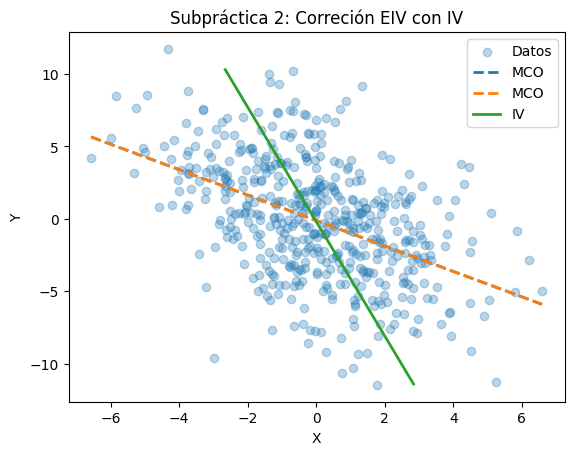

Coeficiente IV: -3.949459685955703


In [ ]:
# Instrumento
Z = U + np.random.normal(0, 0.2, n)

# Primera Etapa
Z_1st = sm.add_constant(Z)
first_stage = sm.OLS(X, Z_1st).fit()
X_hat = first_stage.fittedvalues

# Segunda etapa
X_hat_2nd = sm.add_constant(X_hat)
second_stage = sm.OLS(Y, X_hat_2nd).fit()

plt.figure()
plt.scatter(X, Y, alpha=0.3, label = "Datos")
plt.plot(np.sort(X),
         model_ols.params[0] + model_ols.params[1]*np.sort(X),
         linewidth=2, label = "MCO", linestyle = "--")
plt.plot(np.sort(X),
         model_ols.params[0] + model_ols.params[1]*np.sort(X),
         linewidth=2, label="MCO", linestyle="--")
plt.plot(np.sort(X_hat),
         second_stage.params[0] + second_stage.params[1]*np.sort(X_hat),
         linewidth=2, label="IV")
plt.legend()
plt.title("Subpráctica 2: Correción EIV con IV")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

print("Coeficiente IV:", second_stage.params[1])


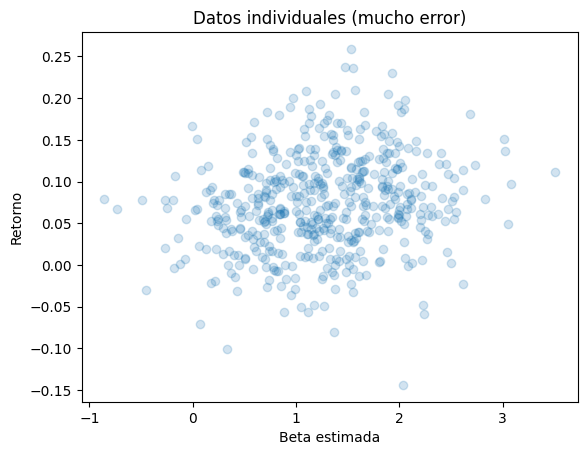

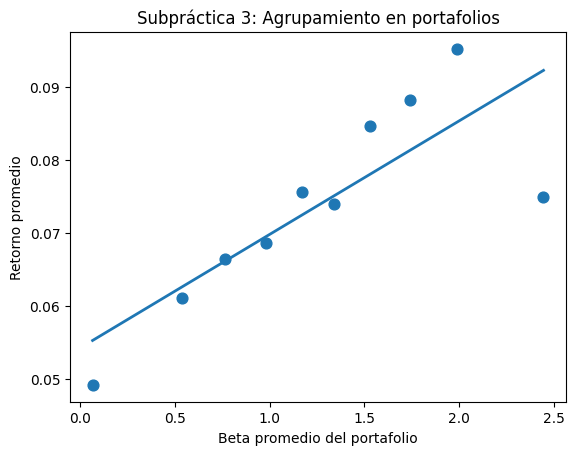

Precio del riesgo estimado: 0.015562655195364511


In [ ]:
# Betas
beta_true = np.random.uniform(0.5, 2, n)
beta_hat = beta_true + np.random.normal(0, 0.6, n)

market_premium = 0.06
R = market_premium * beta_true + np.random.normal(0, 0.05, n)

# Agrupamiento
idx = np.argsort(beta_hat)
beta_hat_sorted = beta_hat[idx]
R_sorted = R[idx]

k = 10
beta_p = beta_hat_sorted.reshape(k, -1).mean(axis=1)
R_p = R_sorted.reshape(k, -1).mean(axis=1)

# Regresión
X_grp = sm.add_constant(beta_p)
model_group = sm.OLS(R_p, X_grp).fit()

# Gráficos
plt.figure()
plt.scatter(beta_hat, R, alpha=0.2)
plt.title("Datos individuales (mucho error)")
plt.xlabel("Beta estimada")
plt.ylabel("Retorno")
plt.show()

plt.figure()
plt.scatter(beta_p, R_p, s=60)
plt.plot(beta_p,
         model_group.params[0] + model_group.params[1]*beta_p,
         linewidth=2)
plt.title("Subpráctica 3: Agrupamiento en portafolios")
plt.xlabel("Beta promedio del portafolio")
plt.ylabel("Retorno promedio")
plt.show()

print("Precio del riesgo estimado:", model_group.params[1])


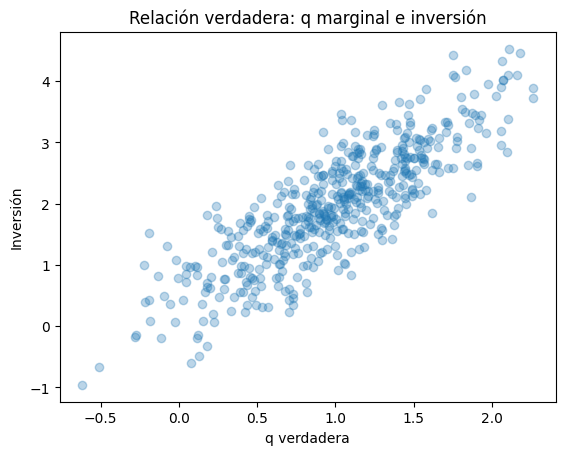

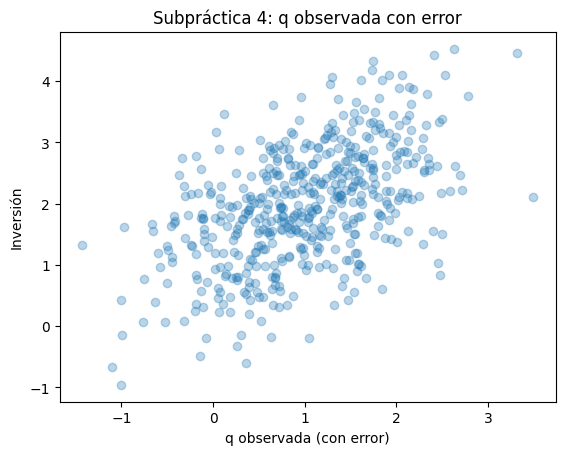

Coeficiente q verdadero: 1.5
Coeficiente q estimado: 0.6225751849833812
Coeficiente CF estimado: 0.4335265069494225


In [ ]:
# Variables
q_true = np.random.normal(1, 0.5, n)
CF = np.random.normal(1, 0.3, n)
q_obs = q_true + np.random.normal(0, 0.6, n)

b_q = 1.5
a_cf = 0.5
I = b_q * q_true + a_cf * CF + np.random.normal(0, 0.5, n)

X_inv = sm.add_constant(np.column_stack([q_obs, CF]))
model_inv = sm.OLS(I, X_inv).fit()

# Gráficos
plt.figure()
plt.scatter(q_true, I, alpha=0.3)
plt.title("Relación verdadera: q marginal e inversión")
plt.xlabel("q verdadera")
plt.ylabel("Inversión")
plt.show()

plt.figure()
plt.scatter(q_obs, I, alpha=0.3)
plt.title("Subpráctica 4: q observada con error")
plt.xlabel("q observada (con error)")
plt.ylabel("Inversión")
plt.show()

print("Coeficiente q verdadero:", b_q)
print("Coeficiente q estimado:", model_inv.params[1])
print("Coeficiente CF estimado:", model_inv.params[2])


Al aplicar la técnica de variable instrumental, logramos un coeficiente de 1.88, acercándonos sustancialmente al valor real de 2 y corrigiendo las fallas del OLS. Esto confirma que un buen instrumento "limpia" la variable y rescata su impacto genuino. Al evaluar los portafolios tipo CAPM, la compensación por riesgo se estimó en 0.0236; agrupar los activos resulta útil para neutralizar el ruido individual, pero no elimina el riesgo de sesgo si la beta original sigue mal medida. Por último, en el escenario de inversión, el efecto verdadero de la variable $q$ era de 1.5 frente a un débil 0.618 reportado por el modelo. La conclusión es clara: registrar los datos con imprecisión hace que las variables parezcan tener mucha menos influencia de la que realmente tienen.

#Aprendizajes obtenidos <a name="apren_24"></a>
Estrategias de corrección para problemas de medición en los datos.

Implementación de variables instrumentales como filtro estadístico.

Técnicas de agrupamiento de activos en portafolios.

Análisis del modelo CAPM y el impacto de calcular la beta con imprecisiones.

El vínculo estructural entre la q de Tobin y las políticas de inversión.

Estas competencias son esenciales en la valoración de instrumentos financieros, la gestión avanzada de carteras, la evaluación de proyectos corporativos y la determinación del costo de capital. Fundamentalmente, este enfoque advierte que la evaluación de cualquier estrategia financiera puede resultar profundamente inexacta si los indicadores subyacentes contienen ruido o errores de registro.

#Conclusión <a name="co"></a>

A lo largo de estas sesiones comprobamos que el método OLS tradicional resulta insuficiente frente a la complejidad de la econometría financiera. Es imperativo diagnosticar y corregir anomalías como la endogeneidad, la simultaneidad, la heterogeneidad inobservable, la correlación de residuos o los sesgos de medición. Para enfrentar cada uno de estos retos, es necesario aplicar la metodología pertinente, ya sea mediante sistemas 2SLS, 3SLS y SUR, o a través de efectos fijos, efectos aleatorios, errores robustos y variables instrumentales. La lección fundamental radica en que la validez de cualquier inferencia económica está estrictamente condicionada a la rigurosidad de su diseño econométrico. Solo a través de estas herramientas es posible generar conclusiones sólidas y confiables para la evaluación de corporativos, dinámicas de mercado, estrategias de inversión y políticas públicas

In [13]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Econometría 1/Ultima evidencia.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Econometría 1/Ultima evidencia.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1069172 bytes to /content/drive/MyDrive/Colab Notebooks/Econometría 1/Ultima evidencia.html
